In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ma'lumotlarni yuklash
df = pd.read_csv('hotel_bookings.csv')

# 2. Asl nusxani xotirada o'zgarishsiz saqlab qolish
df_original = df.copy()

# 3. O'lchamini tekshirish (119,390 qator va 32 ustun chiqishi kerak)
print("Ma'lumotlar o'lchami:", df.shape)

# 4. Ma'lumotlarni o'rganish uchun buyruqlar
print("\n--- Ustunlar va ma'lumot turlari ---")
df.info()

print("\n--- Dastlabki 5 ta qator ---")
display(df.head())

print("\n--- Raqamli ustunlarning statistikasi ---")
display(df.describe())

Ma'lumotlar o'lchami: (119390, 32)

--- Ustunlar va ma'lumot turlari ---
<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies          

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



--- Raqamli ustunlarning statistikasi ---


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [3]:
# 1. Target (Nishon) ustun
print("Target ustun: 'is_canceled'")

# 2. Leakage (Sizib chiqish) dalillari
print("\n--- 1-Leakage dalili: reservation_status ---")
display(pd.crosstab(df['is_canceled'], df['reservation_status']))

print("\n--- 2-Leakage dalili: is_canceled va reservation_status_date ---")
# Bekor qilingan va bekor qilinmaganlarning status o'zgargan sanalaridan namuna
display(df[['is_canceled', 'reservation_status', 'reservation_status_date']].head(5))

# 3. Tanlangan 6 ta Feature uchun daliliy raqamlar
print("\n--- 6 ta Feature dalillari (O'rtacha qiymatlar is_canceled bo'yicha) ---")

# 1. lead_time (oradagi vaqt)
print("\nLead time (kun):")
display(df.groupby('is_canceled')['lead_time'].mean())

# 2. total_of_special_requests (maxsus talablar)
print("\nMaxsus talablar soni:")
display(df.groupby('is_canceled')['total_of_special_requests'].mean())

# 3. previous_cancellations (oldin bekor qilganlik)
print("\nOldingi bekor qilishlar:")
display(df.groupby('is_canceled')['previous_cancellations'].mean())

# 4. deposit_type (depozit turi bo'yicha bekor qilish foizi)
print("\nDepozit turi bo'yicha bekor qilish ehtimoli:")
display(df.groupby('deposit_type')['is_canceled'].mean())

# 5. booking_changes (buyurtmani o'zgartirishlar soni)
print("\nBuyurtmani o'zgartirishlar soni:")
display(df.groupby('is_canceled')['booking_changes'].mean())

# 6. adr (o'rtacha kunlik narx)
print("\nO'rtacha kunlik narx (ADR):")
display(df.groupby('is_canceled')['adr'].mean())

Target ustun: 'is_canceled'

--- 1-Leakage dalili: reservation_status ---


reservation_status,Canceled,Check-Out,No-Show
is_canceled,,,
0,0,75166,0
1,43017,0,1207



--- 2-Leakage dalili: is_canceled va reservation_status_date ---


,is_canceled,reservation_status,reservation_status_date
0,0,Check-Out,2015-07-01
1,0,Check-Out,2015-07-01
2,0,Check-Out,2015-07-02
3,0,Check-Out,2015-07-02
4,0,Check-Out,2015-07-03



--- 6 ta Feature dalillari (O'rtacha qiymatlar is_canceled bo'yicha) ---

Lead time (kun):


...

deposit_type
No Deposit    0.283770
Non Refund    0.993624
Refundable    0.222222
Name: is_canceled, dtype: float64


Buyurtmani o'zgartirishlar soni:


is_canceled
0    0.293364
1    0.098340
Name: booking_changes, dtype: float64


O'rtacha kunlik narx (ADR):


is_canceled
0     99.987693
1    104.964333
Name: adr, dtype: float64

In [4]:
# 1. Bo'sh qiymatlar (Missing values) - country ustuni
print("1. 'country' ustunida bo'sh qatorlar:", df['country'].isnull().sum())

# 2. Bo'sh lekin aslida bo'sh bo'lmagan (Missing that is NOT missing) - company
print("2. 'company' ustunida bo'sh qatorlar:", df['company'].isnull().sum())

# 3. Takrorlangan qatorlar (Repeated rows)
print("3. Takrorlangan qatorlar soni:", df.duplicated().sum())

# 4. Mantiqsiz buyurtmalar (Impossible bookings) - Hech qanday odam yo'q
no_people = df[(df['adults'] == 0) & (df['children'] == 0) & (df['babies'] == 0)]
print("4. Odamlarsiz (0 kattalar, 0 bolalar, 0 chaqaloqlar) buyurtmalar:", len(no_people))

# 5. G'alati raqamlar (Strange numbers) - 0 kun qolish
zero_nights = df[(df['stays_in_week_nights'] == 0) & (df['stays_in_weekend_nights'] == 0)]
print("5. Umumiy qolish muddati 0 kun bo'lgan buyurtmalar:", len(zero_nights))

# 6. Noto'g'ri narxlar (Wrong prices) - Manfiy narx
negative_price = df[df['adr'] < 0]
print("6. Narxi noldan kichik (manfiy) bo'lgan buyurtmalar:", len(negative_price))

# 7. Noto'g'ri narxlar (Wrong prices) - 0 narxli qatorlar
zero_price = df[df['adr'] == 0]
print("7. Narxi 0 ga teng bo'lgan qatorlar:", len(zero_price))

# 8. Bir xil narsaning ikki xil yozilishi (Inconsistent labels) - meal ustuni
print("8. 'meal' ustunidagi qiymatlar:")
print(df['meal'].value_counts())

# 9. Noto'g'ri ma'lumot turlari (Wrong data types) - children ustuni
print("9. 'children' ustunining ma'lumot turi:", df['children'].dtype)

# 10. Noto'g'ri saqlangan sanalar (Badly stored dates)
print("10. Sanalar 3 xil ustunga bo'linib ketgan:")
display(df[['arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month']].head(3))

1. 'country' ustunida bo'sh qatorlar: 488
2. 'company' ustunida bo'sh qatorlar: 112593
3. Takrorlangan qatorlar soni: 31994
4. Odamlarsiz (0 kattalar, 0 bolalar, 0 chaqaloqlar) buyurtmalar: 180
5. Umumiy qolish muddati 0 kun bo'lgan buyurtmalar: 715
6. Narxi noldan kichik (manfiy) bo'lgan buyurtmalar: 1
7. Narxi 0 ga teng bo'lgan qatorlar: 1959
8. 'meal' ustunidagi qiymatlar:
meal
BB           92310
HB           14463
SC           10650
Undefined     1169
FB             798
Name: count, dtype: int64
9. 'children' ustunining ma'lumot turi: float64
10. Sanalar 3 xil ustunga bo'linib ketgan:


,arrival_date_year,arrival_date_month,arrival_date_day_of_month
0,2015,July,1
1,2015,July,1
2,2015,July,1


In [5]:
# 1. TRAP 1: Takrorlangan qatorlar (Repeated rows) analizi
rate_with = df['is_canceled'].mean()
rate_without = df.drop_duplicates()['is_canceled'].mean()
print(f"Takroriylar Bilan bekor qilish foizi: {rate_with:.1%}")
print(f"Takroriylarsiz bekor qilish foizi: {rate_without:.1%}")

# 2. TRAP 2: Narx (adr) dagi outlier'lar (IQR qoidasi)
Q1 = df['adr'].quantile(0.25)
Q3 = df['adr'].quantile(0.75)
IQR = Q3 - Q1
outliers = df[(df['adr'] < (Q1 - 1.5 * IQR)) | (df['adr'] > (Q3 + 1.5 * IQR))]
print(f"\nIQR bo'yicha jami outlier qatorlar: {len(outliers)}")
print(f"Eng katta mantiqsiz narx: {df['adr'].max()}")

# ==================================================
# MA'LUMOTLARNI TOZALASH (CLEANING PROCESS)
# ==================================================
df_clean = df.copy()

# Leakage ustunlarni o'chirish (Part C)
df_clean = df_clean.drop(columns=['reservation_status', 'reservation_status_date'])

# 1. country bo'sh qatorlarini to'ldirish
df_clean['country'] = df_clean['country'].fillna('Unknown')

# 2. company (va agent) bo'sh qatorlarini to'ldirish (0 - id raqami bo'lmasa)
df_clean['company'] = df_clean['company'].fillna(0)
df_clean['agent'] = df_clean['agent'].fillna(0)

# 3. Takrorlangan qatorlarni o'chirish (Trap 1 yechimi)
rows_before = len(df_clean)
df_clean = df_clean.drop_duplicates()

# 4. Odamlarsiz (0) mantiqsiz buyurtmalarni o'chirish
no_people_idx = df_clean[(df_clean['adults'] == 0) & (df_clean['children'] == 0) & (df_clean['babies'] == 0)].index
df_clean = df_clean.drop(no_people_idx)

# 5. 0 kunlik qolishlarni saqlab qolamiz (Day-use bo'lishi mumkinligi uchun tegilmaydi)

# 6 & 7. Narx muammolari (Trap 2 yechimi)
# Manfiy va 5000 dan katta bo'lgan (mantiqsiz) adr ni o'chirish. (0 qoladi)
df_clean = df_clean[(df_clean['adr'] >= 0) & (df_clean['adr'] < 5000)]

# 8. meal ustunidagi Undefined ni SC (Self-Catering) bilan birlashtirish
df_clean['meal'] = df_clean['meal'].replace('Undefined', 'SC')

# 9. children ustunidagi kam sonli NaN ni 0 ga o'zgartirib, turni int ga o'tkazish
df_clean['children'] = df_clean['children'].fillna(0).astype(int)

# 10. Sanalarni bitta haqiqiy DateTime ustuniga aylantirish
month_map = {'January':1, 'February':2, 'March':3, 'April':4, 'May':5, 'June':6, 
             'July':7, 'August':8, 'September':9, 'October':10, 'November':11, 'December':12}
             
date_str = df_clean['arrival_date_year'].astype(str) + '-' + \
           df_clean['arrival_date_month'].map(month_map).astype(str) + '-' + \
           df_clean['arrival_date_day_of_month'].astype(str)
           
df_clean['arrival_date'] = pd.to_datetime(date_str)

# Eski bo'laklangan sana ustunlarini o'chirib yuboramiz
df_clean = df_clean.drop(columns=['arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month', 'arrival_date_week_number'])

print(f"\nTozalashdan keyingi qatorlar soni: {len(df_clean)}")
print(f"Qolgan bo'sh qiymatlar soni: {df_clean.isnull().sum().sum()}")

# 11. Toza faylni saqlash
df_clean.to_csv('hotels_clean.csv', index=False)
print("Fayl 'hotels_clean.csv' nomi bilan muvaffaqiyatli saqlandi!")

Takroriylar Bilan bekor qilish foizi: 37.0%
Takroriylarsiz bekor qilish foizi: 27.5%

IQR bo'yicha jami outlier qatorlar: 3793
Eng katta mantiqsiz narx: 5400.0

Tozalashdan keyingi qatorlar soni: 86970
Qolgan bo'sh qiymatlar soni: 0
Fayl 'hotels_clean.csv' nomi bilan muvaffaqiyatli saqlandi!


In [6]:
# 1. total_nights (Umumiy tunlar)
df_clean['total_nights'] = df_clean['stays_in_week_nights'] + df_clean['stays_in_weekend_nights']

# 2. total_guests (Jami mehmonlar)
df_clean['total_guests'] = df_clean['adults'] + df_clean['children'] + df_clean['babies']

# 3. total_price (Umumiy narx)
df_clean['total_price'] = df_clean['total_nights'] * df_clean['adr']

# 4. is_family (Oilaviy buyurtma - agar bola yoki chaqaloq bo'lsa 1, yo'qsa 0)
df_clean['is_family'] = ((df_clean['children'] > 0) | (df_clean['babies'] > 0)).astype(int)

# --- Hujjat uchun raqamli dalillar (O'rtacha qiymatlar is_canceled bo'yicha) ---
print("1. O'rtacha umumiy tunlar (total_nights):")
display(df_clean.groupby('is_canceled')['total_nights'].mean().round(2))

print("\n2. O'rtacha jami mehmonlar (total_guests):")
display(df_clean.groupby('is_canceled')['total_guests'].mean().round(2))

print("\n3. O'rtacha umumiy narx (total_price):")
display(df_clean.groupby('is_canceled')['total_price'].mean().round(2))

print("\n4. Oilaviy buyurtmalar ulushi (is_family):")
display(df_clean.groupby('is_canceled')['is_family'].mean().round(3))

1. O'rtacha umumiy tunlar (total_nights):


is_canceled
0    3.48
1    4.01
Name: total_nights, dtype: float64


2. O'rtacha jami mehmonlar (total_guests):


is_canceled
0    1.98
1    2.16
Name: total_guests, dtype: float64


3. O'rtacha umumiy narx (total_price):


is_canceled
0    363.30
1    479.65
Name: total_price, dtype: float64


4. Oilaviy buyurtmalar ulushi (is_family):


is_canceled
0    0.095
1    0.131
Name: is_family, dtype: float64

In [7]:
# Q1. Har bir mehmonxonada bekor qilish foizi
print("--- Q1: Mehmonxonalar bo'yicha bekor qilish foizi ---")
q1_res = df_clean.groupby('hotel')['is_canceled'].mean() * 100
display(q1_res.round(1))

# Q2. Qaysi bozor segmenti eng ko'p va eng kam bekor qiladi?
print("\n--- Q2: Market segment bo'yicha bekor qilish foizi ---")
q2_res = df_clean.groupby('market_segment')['is_canceled'].mean() * 100
display(q2_res.sort_values(ascending=False).round(1))

# Q3. Bekor qilinganlarda lead time kattaroqmi? (Mean va Median)
print("\n--- Q3: Lead time (Mean va Median) is_canceled bo'yicha ---")
q3_res = df_clean.groupby('is_canceled')['lead_time'].agg(['mean', 'median'])
display(q3_res.round(1))

# Q4. Har bir mehmonxona qaysi oyda eng qimmat?
print("\n--- Q4: Oylar bo'yicha eng qimmat narxlar ---")
df_clean['month_name'] = df_clean['arrival_date'].dt.month_name()
q4_res = df_clean.groupby(['hotel', 'month_name'])['adr'].mean().reset_index()
# Har bir mehmonxona uchun eng yuqori narxni topish
display(q4_res.loc[q4_res.groupby('hotel')['adr'].idxmax()].round(1))

# Q5. "Non Refund" (Qaytarilmaydigan) bekor qilish foizi
print("\n--- Q5: 'Non Refund' depozitlarining bekor qilish foizi ---")
q5_res = df_clean[df_clean['deposit_type'] == 'Non Refund']['is_canceled'].mean() * 100
print(f"Natija: {q5_res:.1f}%")

# Q6. O'zimizning savol (Bekor qilish haqida): Maxsus talabi (special requests) bor mijozlar kamroq bekor qiladimi?
print("\n--- Q6: Maxsus talabi bor va yo'qlarning bekor qilish foizi ---")
df_clean['has_request'] = df_clean['total_of_special_requests'] > 0
q6_res = df_clean.groupby('has_request')['is_canceled'].mean() * 100
display(q6_res.round(1))

# Q7. O'zimizning savol (Narx haqida): Dam olish kunlari (weekend) qolganlarning o'rtacha narxi qimmatroqmi?
print("\n--- Q7: Dam olish kunlari va oddiy kunlar narxi ---")
df_clean['has_weekend'] = df_clean['stays_in_weekend_nights'] > 0
q7_res = df_clean.groupby('has_weekend')['adr'].mean()
display(q7_res.round(1))

--- Q1: Mehmonxonalar bo'yicha bekor qilish foizi ---


hotel
City Hotel      29.9
Resort Hotel    23.3
Name: is_canceled, dtype: float64


--- Q2: Market segment bo'yicha bekor qilish foizi ---


market_segment
Undefined        100.0
Online TA         35.2
Groups            25.9
Aviation          19.9
Direct            14.7
Offline TA/TO     14.6
Complementary     12.3
Corporate         11.9
Name: is_canceled, dtype: float64


--- Q3: Lead time (Mean va Median) is_canceled bo'yicha ---


...

,hotel,month_name,adr
8,City Hotel,May,128.1
13,Resort Hotel,August,187.5



--- Q5: 'Non Refund' depozitlarining bekor qilish foizi ---
Natija: 94.6%

--- Q6: Maxsus talabi bor va yo'qlarning bekor qilish foizi ---


has_request
False    32.9
True     21.7
Name: is_canceled, dtype: float64


--- Q7: Dam olish kunlari va oddiy kunlar narxi ---


has_weekend
False    102.4
True     109.2
Name: adr, dtype: float64

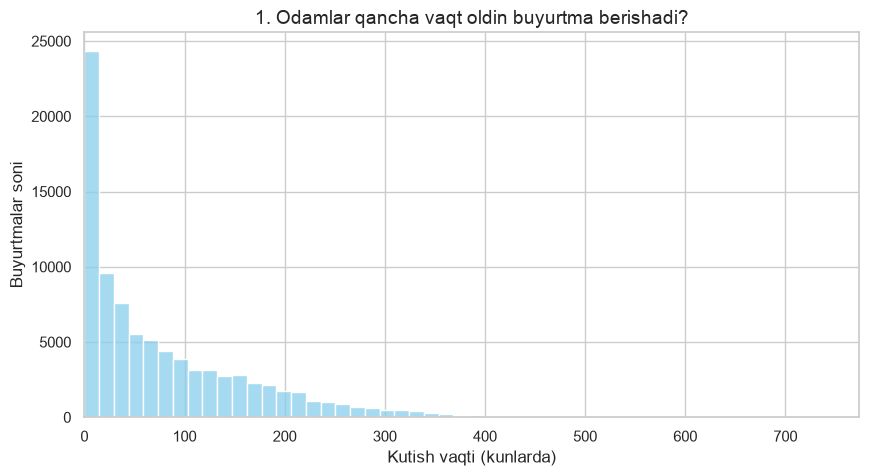

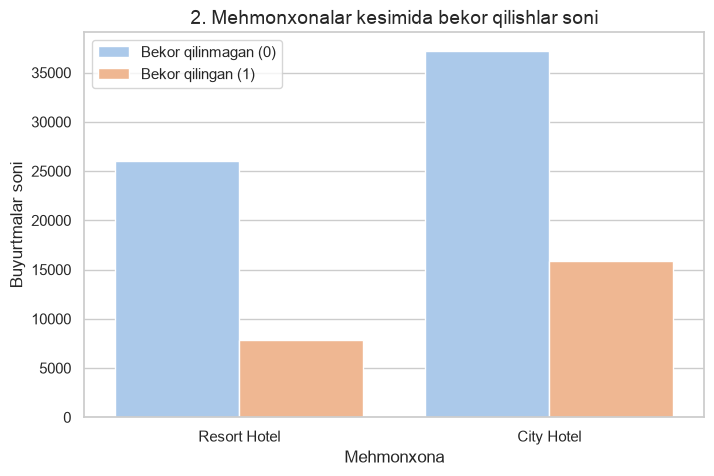

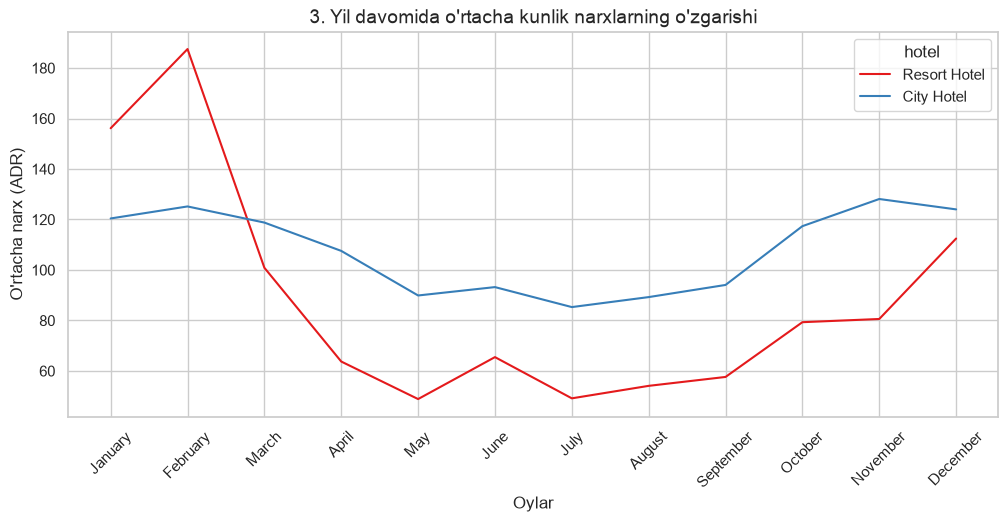

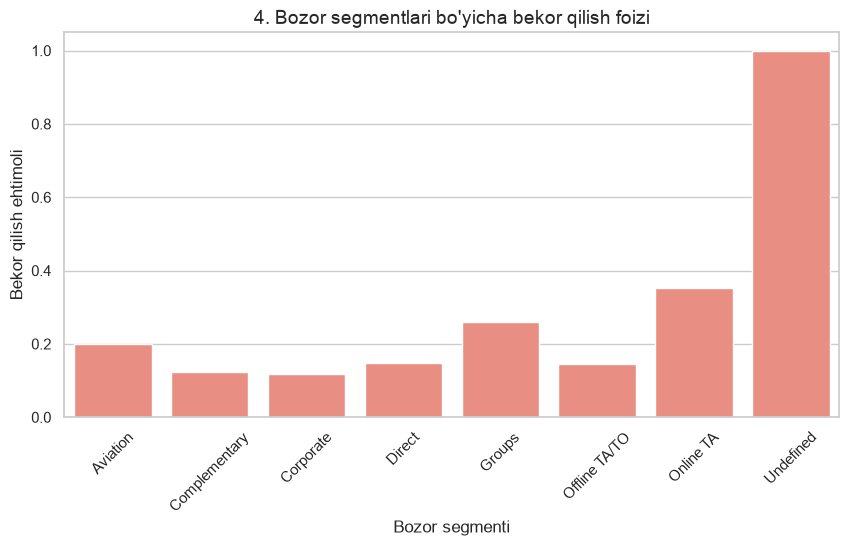

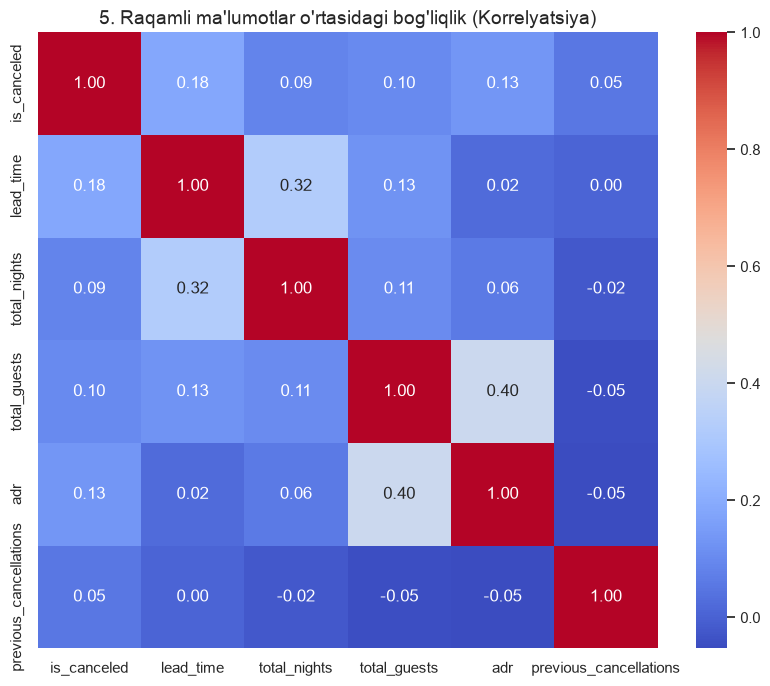

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Grafiklar dizaynini yaxshilash
sns.set_theme(style="whitegrid")

# 1. Odamlar qancha vaqt oldin buyurtma berishadi?
plt.figure(figsize=(10, 5))
sns.histplot(df_clean['lead_time'], bins=50, color='skyblue')
plt.title("1. Odamlar qancha vaqt oldin buyurtma berishadi?", fontsize=14)
plt.xlabel("Kutish vaqti (kunlarda)", fontsize=12)
plt.ylabel("Buyurtmalar soni", fontsize=12)
plt.xlim(0) # 0 dan boshlash
plt.show()

# 2. Qaysi mehmonxonada bekor qilishlar ko'proq?
plt.figure(figsize=(8, 5))
sns.countplot(data=df_clean, x='hotel', hue='is_canceled', palette='pastel')
plt.title("2. Mehmonxonalar kesimida bekor qilishlar soni", fontsize=14)
plt.xlabel("Mehmonxona", fontsize=12)
plt.ylabel("Buyurtmalar soni", fontsize=12)
plt.legend(['Bekor qilinmagan (0)', 'Bekor qilingan (1)'])
plt.show()

# 3. Yil davomida narxlar qanday o'zgaradi? (Oylar to'g'ri tartibda)
oylar_tartibi = ['January', 'February', 'March', 'April', 'May', 'June', 
                 'July', 'August', 'September', 'October', 'November', 'December']
plt.figure(figsize=(12, 5))
sns.lineplot(data=df_clean, x='month_name', y='adr', hue='hotel', palette='Set1', errorbar=None)
plt.xticks(ticks=range(12), labels=oylar_tartibi, rotation=45)
plt.title("3. Yil davomida o'rtacha kunlik narxlarning o'zgarishi", fontsize=14)
plt.xlabel("Oylar", fontsize=12)
plt.ylabel("O'rtacha narx (ADR)", fontsize=12)
plt.show()

# 4. Qaysi bozor segmentlari eng ko'p bekor qiladi?
plt.figure(figsize=(10, 5))
segment_data = df_clean.groupby('market_segment')['is_canceled'].mean().reset_index()
sns.barplot(data=segment_data, x='market_segment', y='is_canceled', color='salmon')
plt.title("4. Bozor segmentlari bo'yicha bekor qilish foizi", fontsize=14)
plt.xlabel("Bozor segmenti", fontsize=12)
plt.ylabel("Bekor qilish ehtimoli", fontsize=12)
plt.xticks(rotation=45)
plt.show()

# 5. Raqamli ustunlar orasidagi bog'liqlik
plt.figure(figsize=(10, 8))
raqamli_ustunlar = df_clean.select_dtypes(include=['int64', 'float64', 'int32']).columns
# is_canceled, adr, total_nights, lead_time kabi muhimlarini ajratib olamiz
muhim_ustunlar = ['is_canceled', 'lead_time', 'total_nights', 'total_guests', 'adr', 'previous_cancellations']
sns.heatmap(df_clean[muhim_ustunlar].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("5. Raqamli ma'lumotlar o'rtasidagi bog'liqlik (Korrelyatsiya)", fontsize=14)
plt.show()